# 06 — Results Comparison & Discussion

**Inputs:** all `artifacts/metrics_*.json` files  
**Outputs:** consolidated result tables, comparison figures, and a draft Chapter 5 paragraph  
**Feeds thesis:** Chapter 5 — Results and Discussion

This notebook assembles every result from Notebooks 3–5 into the final tables and
figures that will appear in the thesis. It also auto-generates a draft results
paragraph based on the actual numbers — you edit it into fluent prose.

## 1. Setup

In [1]:
import pandas as pd, numpy as np, json, os
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

required = {
    'eda':      '../artifacts/eda_summary.json',
    'split':    '../artifacts/split_info.json',
    'baseline': '../artifacts/metrics_tfidf.json',
    'sbert':    '../artifacts/metrics_sbert.json',
    'bertopic': '../artifacts/metrics_bertopic.json',
}
missing = [k for k, p in required.items() if not os.path.exists(p)]
if missing:
    print('Missing artifacts:', missing)
    print('Run Notebooks 1-5 first.')
else:
    print('All required artifacts present.')

All required artifacts present.


## 2. Load all metrics

In [2]:
def load(path, default=None):
    return json.load(open(path)) if os.path.exists(path) else default

eda      = load(required['eda'])
split    = load(required['split'])
m_base   = load(required['baseline'])
m_sbert  = load(required['sbert'])
m_hybrid = load('../artifacts/metrics_hybrid.json')     # optional
m_topic  = load(required['bertopic'])

print('Loaded:')
for name, obj in [('EDA', eda), ('Split', split), ('Baseline', m_base),
                  ('SBERT', m_sbert), ('Hybrid', m_hybrid), ('BERTopic', m_topic)]:
    print(f'  {name:>10s}: {"OK" if obj else "MISSING"}')

Loaded:
         EDA: OK
       Split: OK
    Baseline: OK
       SBERT: OK
      Hybrid: OK
    BERTopic: OK


## 3. Table 1 — Dataset summary

In [3]:
rows = [
    ('Total sentences (raw)',         eda['raw_rows']),
    ('Relevant sentences',            eda['relevant']),
    ('Non-relevant sentences',        eda['non_relevant']),
    ('Imbalance ratio',               f"{eda['imbalance_ratio']}:1"),
    ('Documents',                     eda['num_documents']),
    ('Sources',                       eda['num_sources']),
    ('Mean sentence length (words)',  eda['avg_words']),
    ('Median sentence length (words)',eda['median_words']),
    ('Vocabulary size',               eda['vocab_size']),
    ('Type-token ratio',              eda['type_token_ratio']),
    ('Hapax legomena (%)',            eda['hapax_pct']),
    ('Train sentences',         split['train_size']),
    ('Test sentences',          split['test_size']),
    ('Train documents',               split['train_docs']),
    ('Test documents',                split['test_docs']),
    ('Document overlap',              split['overlap_docs']),
]
table1 = pd.DataFrame(rows, columns=['Attribute', 'Value'])
print(table1.to_string(index=False))
table1.to_csv('../artifacts/table_dataset_summary.csv', index=False)

                     Attribute   Value
         Total sentences (raw)   12304
            Relevant sentences    4302
        Non-relevant sentences    8002
               Imbalance ratio  1.86:1
                     Documents     100
                       Sources       5
  Mean sentence length (words)    21.7
Median sentence length (words)    19.0
               Vocabulary size   13292
              Type-token ratio  0.0599
            Hapax legomena (%)   37.64
               Train sentences    9020
                Test sentences    3284
               Train documents      77
                Test documents      23
              Document overlap       0


## 4. Table 2 — Classification comparison

In [4]:
# Classification metrics for every supervised classifier (test set)
# Accuracy is included for TF-IDF, SBERT, and Hybrid. BERTopic is unsupervised,
# so classification accuracy is not applicable unless ground-truth topic labels exist.
classification_models = [
    ("TF-IDF baseline", m_base),
    ("SBERT", m_sbert),
    ("Hybrid", m_hybrid),
]
rows = []
for display_name, metrics in classification_models:
    if not metrics:
        print(f"Skipping {display_name}: metrics file missing.")
        continue
    rows.append({
        'model': metrics.get('model', display_name),
        'accuracy': metrics.get('accuracy', np.nan),
        'precision': metrics.get('precision', np.nan),
        'recall': metrics.get('recall', np.nan),
        'macro_f1': metrics.get('macro_f1', np.nan),
        'weighted_f1': metrics.get('weighted_f1', np.nan),
    })

if not rows:
    raise ValueError("No classification metrics loaded. Run Notebooks 3 and 4 first.")

table2 = pd.DataFrame(rows)[
    ['model', 'accuracy', 'precision', 'recall', 'macro_f1', 'weighted_f1']
].round(4)
table2.to_csv('../artifacts/table_classification.csv', index=False)
print("TEST-SET CLASSIFICATION METRICS (higher is better; scores range 0–1):")
print(table2.to_string(index=False))

print("\nTest accuracy by model:")
for _, row in table2.iterrows():
    if pd.notna(row['accuracy']):
        print(f"  {row['model']}: {row['accuracy']:.4f} ({row['accuracy']:.2%})")
    else:
        print(f"  {row['model']}: accuracy not available in metrics JSON")

best_idx = table2['macro_f1'].idxmax()
print(f"\nBest model by macro-F1: {table2.loc[best_idx, 'model']} "
      f"(macro-F1 = {table2.loc[best_idx, 'macro_f1']:.4f})")

TEST-SET CLASSIFICATION METRICS (higher is better; scores range 0–1):
                                   model  accuracy  precision  recall  macro_f1  weighted_f1
LinearSVC (C=0.3, class_weight=balanced)    0.7463     0.6269  0.6605    0.7232       0.7478
                       SBERT + LinearSVC    0.7268     0.5881  0.7190    0.7121       0.7318
     Hybrid (TF-IDF + SBERT) + LinearSVC    0.7675     0.6576  0.6933    0.7470       0.7689

Test accuracy by model:
  LinearSVC (C=0.3, class_weight=balanced): 0.7463 (74.63%)
  SBERT + LinearSVC: 0.7268 (72.68%)
  Hybrid (TF-IDF + SBERT) + LinearSVC: 0.7675 (76.75%)

Best model by macro-F1: Hybrid (TF-IDF + SBERT) + LinearSVC (macro-F1 = 0.7470)


## 5. Table 3 — Topic discovery (BERTopic)

BERTopic is an unsupervised topic-discovery method, not a supervised classifier. Its
accuracy (%) is **not applicable** unless each discovered topic can be matched to reliable
ground-truth labels. Report topic count, coherence, diversity, and outlier count instead.

In [5]:
table3 = pd.DataFrame([{
    'Metric': ['Topics discovered', 'Coherence (c_v)', 'Diversity',
               'Outlier sentences', 'Min cluster size'],
    'Value':  [m_topic['n_topics'], m_topic['coherence_cv'], m_topic['diversity'],
               m_topic['n_outliers'], m_topic['min_cluster_size']]
}])
print(table3.to_string(index=False))
table3.to_csv('../artifacts/table_topic_discovery.csv', index=False)

print(f"\nTopic coherence = {m_topic['coherence_cv']:.4f} "
      f"({'good' if m_topic['coherence_cv']>=0.5 else 'acceptable' if m_topic['coherence_cv']>=0.3 else 'weak'})")
print(f"Topic diversity = {m_topic['diversity']:.4f} "
      f"({'good' if m_topic['diversity']>=0.7 else 'acceptable'})")

                                                                              Metric                          Value
[Topics discovered, Coherence (c_v), Diversity, Outlier sentences, Min cluster size] [24, 0.4659, 0.7917, 1594, 20]

Topic coherence = 0.4659 (acceptable)
Topic diversity = 0.7917 (good)


## 6. Figure 1 — Classification comparison

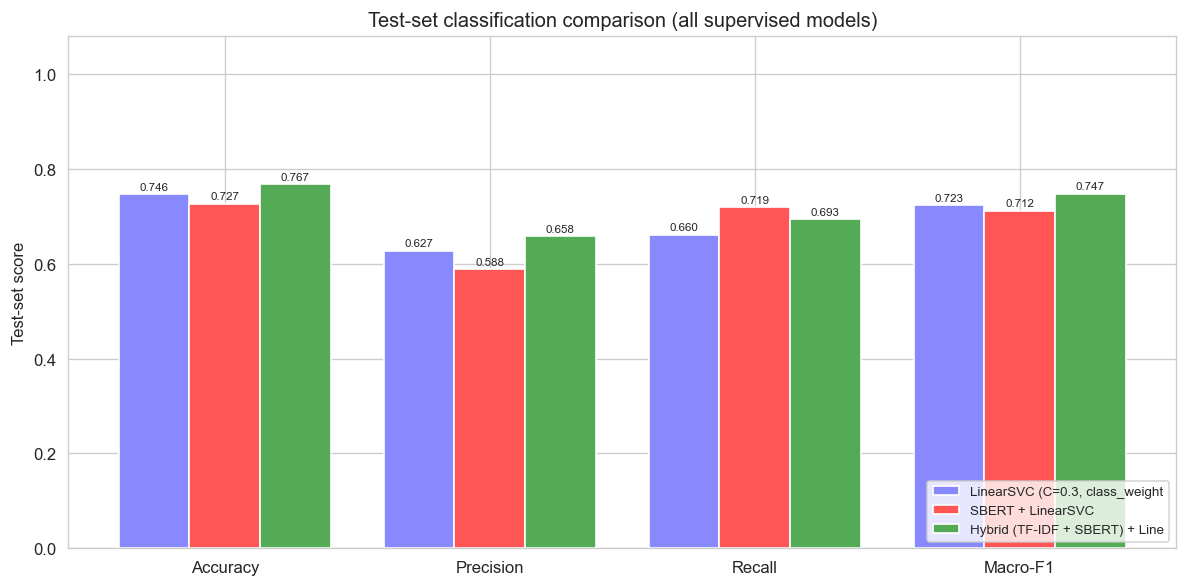

saved -> artifacts/figs/fig_classification_comparison.png


In [6]:
# Compare all supervised classifiers on the test set, including accuracy.
metrics_cols = ['accuracy', 'precision', 'recall', 'macro_f1']
x = np.arange(len(metrics_cols))
n_models = len(table2)
w = 0.8 / n_models
colors = ['#8888ff', '#ff5555', '#55aa55'][:n_models]

fig, ax = plt.subplots(figsize=(10, 5))
for i, (_, row) in enumerate(table2.iterrows()):
    vals = [row[k] for k in metrics_cols]
    ax.bar(x + (i - (n_models-1)/2)*w, vals, w,
           label=str(row['model'])[:30], color=colors[i])
    for j, v in enumerate(vals):
        if pd.notna(v):
            ax.text(j + (i - (n_models-1)/2)*w, v + 0.01, f'{v:.3f}',
                    ha='center', fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'Macro-F1'])
ax.set_ylim(0, 1.08)
ax.set_ylabel('Test-set score')
ax.set_title('Test-set classification comparison (all supervised models)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_classification_comparison.png')
plt.show()
print('saved -> artifacts/figs/fig_classification_comparison.png')

## 7. Figure 2 — Dataset composition

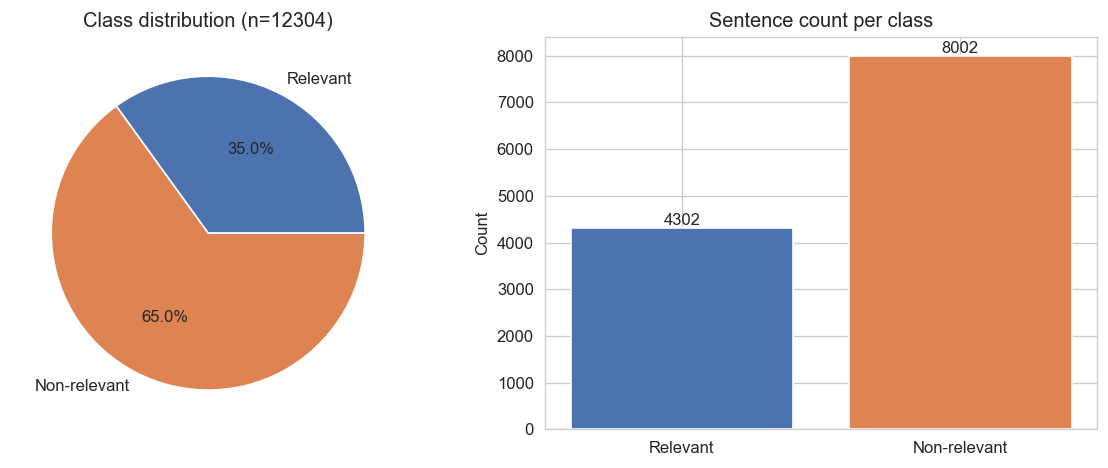

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].pie([eda['relevant'], eda['non_relevant']],
            labels=['Relevant','Non-relevant'],
            autopct='%1.1f%%', colors=['#4c72b0','#dd8452'])
axes[0].set_title(f"Class distribution (n={eda['raw_rows']})")

bars = [eda['relevant'], eda['non_relevant']]
axes[1].bar(['Relevant','Non-relevant'], bars, color=['#4c72b0','#dd8452'])
for i, v in enumerate(bars):
    axes[1].text(i, v, str(v), ha='center', va='bottom')
axes[1].set_ylabel('Count'); axes[1].set_title('Sentence count per class')
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_dataset_summary.png')
plt.show()

## 8. Figure 3 — Per-metric delta vs baseline

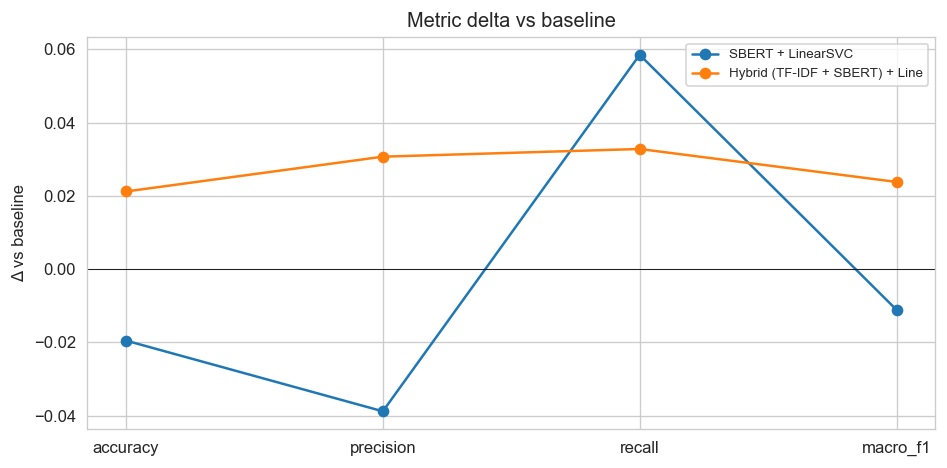

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
base_row = table2.iloc[0]
for i, (_, row) in enumerate(table2.iloc[1:].iterrows(), start=1):
    deltas = [row[k] - base_row[k] for k in metrics_cols]
    ax.plot(metrics_cols, deltas, marker='o', label=row['model'][:30])
ax.axhline(0, color='black', linewidth=0.5)
ax.set_ylabel('Δ vs baseline'); ax.set_title('Metric delta vs baseline')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_metric_delta.png')
plt.show()

## 9. Final summary

In [9]:
print('=' * 70)
print(f"{'THESIS RESULTS SUMMARY':^70s}")
print('=' * 70)
print(f"Dataset            : SMAH-CTI ({eda['raw_rows']} sentences, {eda['num_documents']} docs)")
print(f"Split              : {split['train_size']} train / {split['test_size']} test")
print()
print('CLASSIFICATION — TEST-SET RESULTS:')
for _, row in table2.iterrows():
    acc = f"accuracy = {row['accuracy']:.4f} ({row['accuracy']:.2%})" if pd.notna(row['accuracy']) else 'accuracy = unavailable'
    print(f"  {str(row['model'])[:28]:<28s}  {acc}; macro-F1 = {row['macro_f1']:.4f}")
print()
print('TOPIC DISCOVERY (BERTopic; accuracy not applicable without ground-truth topic labels):')
print(f"  Topics            = {m_topic['n_topics']}")
print(f"  Coherence (c_v)   = {m_topic['coherence_cv']:.4f}")
print(f"  Diversity         = {m_topic['diversity']:.4f}")
print('=' * 70)

                        THESIS RESULTS SUMMARY                        
Dataset            : SMAH-CTI (12304 sentences, 100 docs)
Split              : 9020 train / 3284 test

CLASSIFICATION — TEST-SET RESULTS:
  LinearSVC (C=0.3, class_weig  accuracy = 0.7463 (74.63%); macro-F1 = 0.7232
  SBERT + LinearSVC             accuracy = 0.7268 (72.68%); macro-F1 = 0.7121
  Hybrid (TF-IDF + SBERT) + Li  accuracy = 0.7675 (76.75%); macro-F1 = 0.7470

TOPIC DISCOVERY (BERTopic; accuracy not applicable without ground-truth topic labels):
  Topics            = 24
  Coherence (c_v)   = 0.4659
  Diversity         = 0.7917


## Accuracy and evaluation metrics as percentages
This cell converts the saved classification metrics from decimals (for example, 0.85) to percentages (85.00%). It reads actual results from the artifacts folder; it does not set or assume a 100% accuracy score. BERTopic is excluded because it is a topic-discovery model and does not have classification accuracy unless ground-truth topic labels are available.

,Model,Test Accuracy (%),Precision (%),Recall (%),Macro-F1 (%),Weighted-F1 (%)
0,TF-IDF baseline,74.63%,62.69%,66.05%,72.32%,74.78%
1,SBERT,72.68%,58.81%,71.90%,71.21%,73.18%
2,Hybrid,76.75%,65.76%,69.33%,74.70%,76.89%


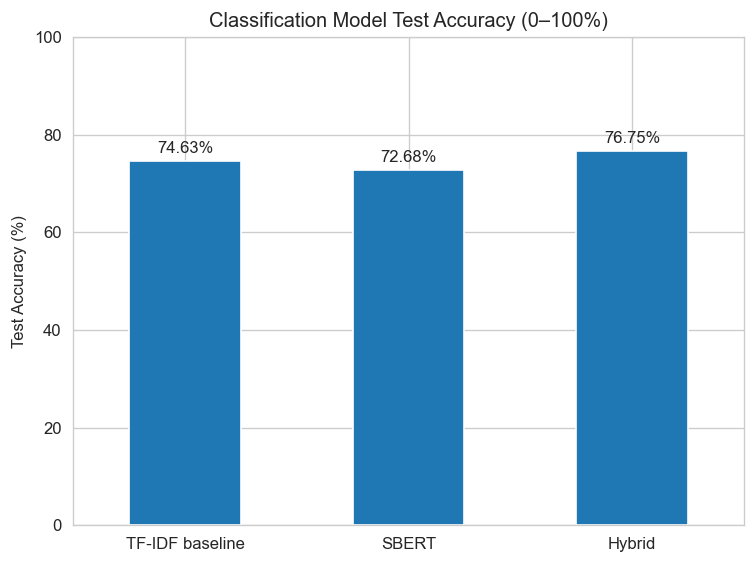


Accuracy in percentage terms:
TF-IDF baseline: 74.63%
SBERT: 72.68%
Hybrid: 76.75%


In [11]:
# Display classification accuracy in percentage terms (0–100%)
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ARTIFACTS = Path("../artifacts")
model_files = {
    "TF-IDF baseline": "metrics_tfidf.json",
    "SBERT": "metrics_sbert.json",
    "Hybrid": "metrics_hybrid.json",
}

percent_rows = []
for model_name, filename in model_files.items():
    metric_path = ARTIFACTS / filename
    if not metric_path.exists():
        print(f"Missing metrics file: {metric_path} — run the corresponding model notebook first.")
        continue

    with metric_path.open("r", encoding="utf-8") as f:
        metrics = json.load(f)

    accuracy = metrics.get("accuracy")
    if accuracy is None:
        print(f"No 'accuracy' value found in {metric_path}.")
        continue

    percent_rows.append({
        "Model": model_name,
        "Test Accuracy (%)": float(accuracy) * 100,
        "Precision (%)": float(metrics["precision"]) * 100 if metrics.get("precision") is not None else None,
        "Recall (%)": float(metrics["recall"]) * 100 if metrics.get("recall") is not None else None,
        "Macro-F1 (%)": float(metrics["macro_f1"]) * 100 if metrics.get("macro_f1") is not None else None,
        "Weighted-F1 (%)": float(metrics["weighted_f1"]) * 100 if metrics.get("weighted_f1") is not None else None,
    })

percent_results = pd.DataFrame(percent_rows)
if percent_results.empty:
    print("No classification metrics found. Run notebooks 03 and 04 first.")
else:
    display(percent_results.style.format({
        col: "{:.2f}%" for col in percent_results.columns if col != "Model"
    }))

    ax = percent_results.plot(
        x="Model", y="Test Accuracy (%)", kind="bar",
        legend=False, ylim=(0, 100), rot=0
    )
    ax.set_ylabel("Test Accuracy (%)")
    ax.set_xlabel("")
    ax.set_title("Classification Model Test Accuracy (0–100%)")
    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
    plt.tight_layout()
    plt.show()

    print("\nAccuracy in percentage terms:")
    for _, row in percent_results.iterrows():
        print(f"{row['Model']}: {row['Test Accuracy (%)']:.2f}%")


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Your model accuracy results (%)
your_results = {
    "TF-IDF Baseline": 74.63,
    "SBERT": 72.68,
    "Hybrid Model": 76.75
}

# Research paper results (%)
paper_results = {
    "BOW + SVM (Binary)": 93.67,
    "BOW + SVM (Term Frequency)": 92.75,
    "TF-IDF Unigram + SVM": 90.69,
    "Word2Vec + LSTM": 93.13,
    "Doc2Vec + LSTM": 88.90
}